In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
from tabulate import tabulate

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch

# Custom modules
import LSTM
import Dataset
import utils


# Set SEED
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


## Data loading

In [22]:
df = pd.read_parquet('../Data/LOBSTER/AMZN.parquet')
df = df.head(20000)
trarget_cols = ['MP']

df = utils.FeaturesExtractionLOB(df).extract()

# df = pd.read_parquet('../Data/Toy Datasets/sinewave.parquet')
df.head()

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Ask_10,P_Bid_10,V_Bid_10,MP,WMP,Spread,Imbalance,Depth_Bid,Depth_Ask,Depth_Total
0,2239500,100,2231800,100,2239900,100,2230700,200,2240000,220,...,100,2189700,100,2235650.0,2.235650e+06,7700,0.000000,9810,1567,11377
1,2239500,100,2238100,21,2239900,100,2231800,100,2240000,220,...,100,2202000,100,2238800.0,2.239257e+06,1400,0.652893,9731,1567,11298
2,2239500,100,2238100,21,2239600,20,2231800,100,2239900,100,...,100,2202000,100,2238800.0,2.239257e+06,1400,0.652893,9731,1487,11218
3,2239500,100,2238100,21,2239600,20,2237500,100,2239900,100,...,100,2202500,5000,2238800.0,2.239257e+06,1400,0.652893,9731,1487,11218
4,2239500,100,2238100,21,2239600,20,2237500,100,2239900,100,...,100,2202500,5000,2238800.0,2.239257e+06,1400,0.652893,9731,1500,11231


In [23]:
# Split the dataframe into train and test
df_train, df_test = train_test_split(df, test_size=0.2, shuffle=False)
df_train, df_val = train_test_split(df_train, test_size=0.2, shuffle=False)

# Standardize the data
scaler = StandardScaler()
df_train[df_train.columns] = scaler.fit_transform(df_train)
df_val[df_val.columns] = scaler.transform(df_val)
df_test[df_test.columns] = scaler.transform(df_test)

# Split covariates and response
X_train, y_train = df_train.drop(columns=trarget_cols).values , df_train[trarget_cols].values
X_val, y_val     = df_val.drop(columns=trarget_cols).values   , df_val[trarget_cols].values
X_test, y_test   = df_test.drop(columns=trarget_cols).values  , df_test[trarget_cols].values

# Standardize the covariates
# scaler_X = StandardScaler()
# X_train = scaler_X.fit_transform(X_train)
# X_val = scaler_X.transform(X_val)
# X_test = scaler_X.transform(X_test)

# Build tensors 
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train = torch.tensor(y_train, dtype=torch.float32).to(device)
X_val = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val = torch.tensor(y_val, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test = torch.tensor(y_test, dtype=torch.float32).to(device)

# Build TimeSeriesDataset
SEQ_LEN_X = 100
SEQ_LEN_Y = 5
OFFSET = 100
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False
)

# Build TimeSeriesLoader
BATCH_SIZE = 64
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = BATCH_SIZE,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = BATCH_SIZE,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = BATCH_SIZE,
    shuffle = False
)

In [24]:
print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 12600 samples
Test dataset: 3800 samples


## Model

In [25]:
# define hyperparameters
INPUT_SIZE = X_train.shape[-1]
OUTPUT_SIZE = y_train.shape[-1]
LSTM_SIZE = 64
HIDDEN_SIZE = 32
LSTM_LAYERS = 2
DROPOUT = 0.0
NUM_CHANNELS = 2

# Show hyperparameters in a pretty table
table = [
    ["INPUT_SIZE", INPUT_SIZE],
    ["OUTPUT_SIZE", OUTPUT_SIZE],
    ["HIDDEN_SIZE", HIDDEN_SIZE],
    ["LSTM_LAYERS", LSTM_LAYERS],
    ["DROPOUT", DROPOUT],
]
print(tabulate(table, headers=["Parameter", "Value"], tablefmt="pretty"))

# create the model
model = LSTM.Astice(
    input_size  = INPUT_SIZE,
    output_size = OUTPUT_SIZE,
    hidden_size = HIDDEN_SIZE,
    lstm_size   = LSTM_SIZE,
    lstm_layers = LSTM_LAYERS,
    seq_len_out = SEQ_LEN_Y,
    smooth_conv_channels = 2
).to(device)

+-------------+-------+
|  Parameter  | Value |
+-------------+-------+
| INPUT_SIZE  |  46   |
| OUTPUT_SIZE |   1   |
| HIDDEN_SIZE |  32   |
| LSTM_LAYERS |   2   |
|   DROPOUT   |  0.0  |
+-------------+-------+


### Training

In [26]:
NUM_EPOCHS = 10
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = torch.nn.MSELoss()
# criterion = torch.nn.CrossEntropyLoss()

progress_bar = tqdm(range(NUM_EPOCHS), desc="Training")
losses_train = []
losses_val = []
for i in progress_bar:
    model.train()
    for X_batch, y_batch in dataloader_train:
        optimizer.zero_grad()
        y_pred = model(X_batch)        
        loss = criterion(y_pred, y_batch)
        loss.backward()
        optimizer.step()
    
    # Compute the train and validation loss
    model.eval()
    
    # Compute the train loss
    with torch.no_grad():
        loss_train = 0
        for X_batch, y_batch in dataloader_train:
            y_pred = model(X_batch)
            loss_train += criterion(y_pred, y_batch).item()
        loss_train /= len(dataloader_train)
        losses_train.append(loss_train)
    # Compute the validation loss
    with torch.no_grad():
        loss_val = 0
        for X_batch, y_batch in dataloader_val:
            y_pred = model(X_batch)
            loss_val += criterion(y_pred, y_batch).item()
        loss_val /= len(dataloader_val)
        losses_val.append(loss_val)
        
    progress_bar.set_postfix({'loss_train': loss_train, 'loss_val': loss_val})


losses_train = np.array(losses_train)
losses_val = np.array(losses_val)

Training:   0%|          | 0/10 [00:00<?, ?it/s]

Total number of parameters:  78309
Last training loss: 0.09791230909564168
Last validation loss: 0.10851898302443008


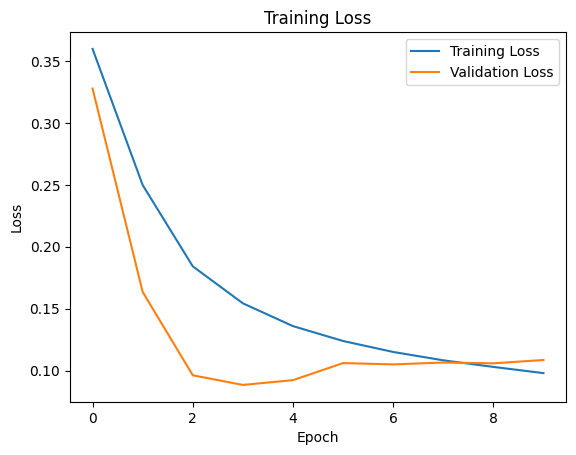

In [27]:
print('Total number of parameters: ', sum(p.numel() for p in model.parameters()))

print("Last training loss:", losses_train[-1])
print("Last validation loss:", losses_val[-1])

plt.plot(losses_train, label='Training Loss')
plt.plot(losses_val, label='Validation Loss')
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [28]:
# predict test set and calculate loss
model.eval()
loss_test = 0
preds = []
true = []
with torch.no_grad():
    for X_batch, y_batch in dataloader_test:
        y_pred = model(X_batch)
        loss_test += criterion(y_pred, y_batch).item()
        preds.append( y_pred.cpu().numpy() )
        true.append( y_batch.cpu().numpy() )
loss_test /= len(dataloader_test)
print(f"Test Loss: {loss_test}")

preds = np.concatenate(preds, axis=0)
true = np.concatenate(true, axis=0)

Test Loss: 0.22308021097754438


In [29]:
def sMAPE(y_true, y_pred):
    epsilon = 1e-10  # Small constant to avoid division by zero
    return np.mean( 2.0 * np.abs(y_true - y_pred) / (np.abs(y_true) + np.abs(y_pred) + epsilon) )

print("sMAPE:", round(sMAPE(true, preds)*100,1) )

sMAPE: 42.6


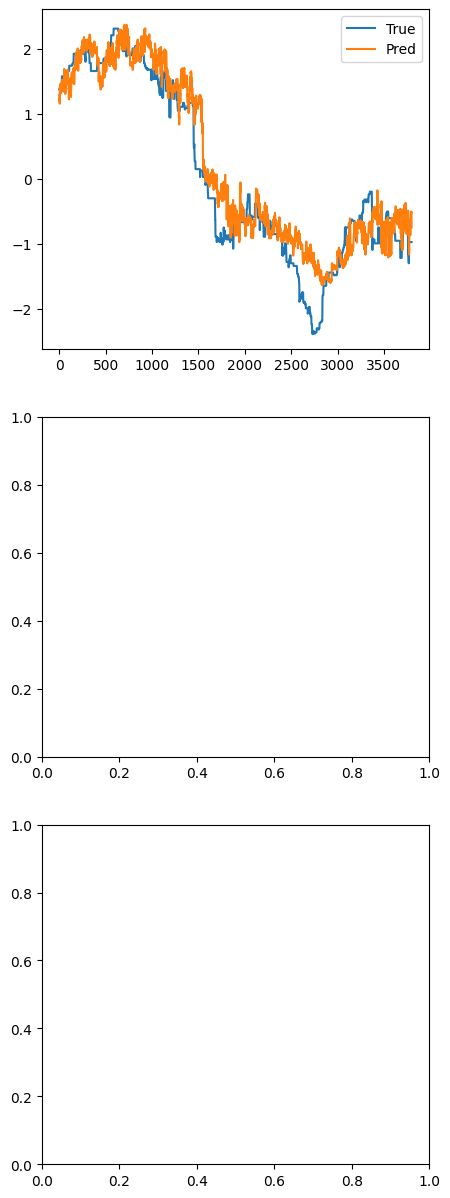

In [30]:
true, pred = true[:,0,:], preds[:,0,:]
fig, ax = plt.subplots(3, 1, figsize=(5, 15))
for i in range(true.shape[-1]):
    ax[i].plot(true[:,i], label="True")
    ax[i].plot(pred[:,i], label="Pred")
    ax[i].legend()
plt.show()

torch.Size([64, 100, 46]) torch.Size([64, 5, 1])


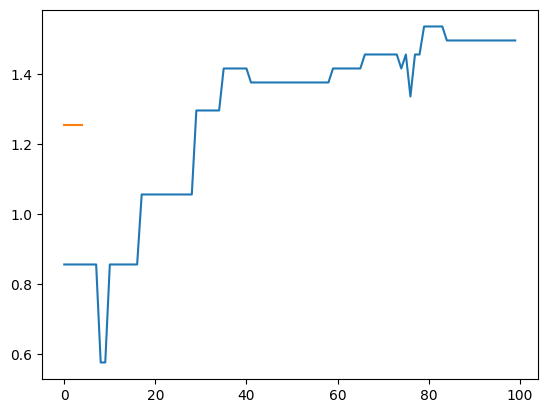

In [31]:
for x,x_hat in dataloader_train:
    print(x.shape, x_hat.shape)
    plt.plot(x[0,:,0].cpu().numpy())
    plt.plot(x_hat[0,:,0].cpu().numpy())
    break